## Title: Heart Disease Prediction
Author: Muhammad Talha Imran\
[Linkedin](https://www.linkedin.com/in/talha-imran-ai)\
[Github](https://github.com/mtalhaimran104)\
Date: 10.Oct.2026

### Import Libraries
Let's start importing libraries used in project

In [3]:
# import libraries

# To handle the data
import pandas as pd
import numpy as np

# To visualize the dataset
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.express import scatter

# To preprocess the data
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer, KNNImputer

# import iterative imputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

# For classification task
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# import warnings
import warnings
warnings.filterwarnings('ignore')

### Load the dataset

In [4]:
# Load dataset
df = pd.read_csv('dataset/heart_disease_uci.csv')
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


### Exploratory Data Analysis (EDA)

In [5]:
# exploring the datatype of each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [6]:
# data shape
df.shape

(920, 16)

In [7]:
# id column
df['id'].min(), df['id'].max()

(np.int64(1), np.int64(920))

In [8]:
# age column

# for minimum age
print("Minimum age is:",df['age'].min())

# for maximum age
print("Maximum age is:", df['age'].max())

Minimum age is: 28
Maximum age is: 77


In [9]:
# summarize the age column
df['age'].describe()

count    920.000000
mean      53.510870
std        9.424685
min       28.000000
25%       47.000000
50%       54.000000
75%       60.000000
max       77.000000
Name: age, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

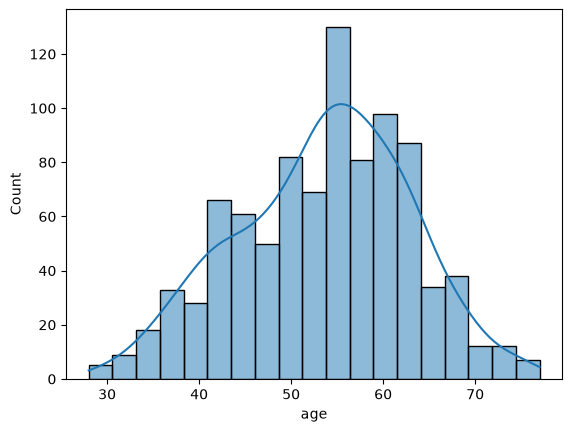

In [10]:
# draw a histogram to see distribution of age column
sns.histplot(df['age'], kde= True)

Mean: 53.51086956521739
Median: 54.0
Mode: 54


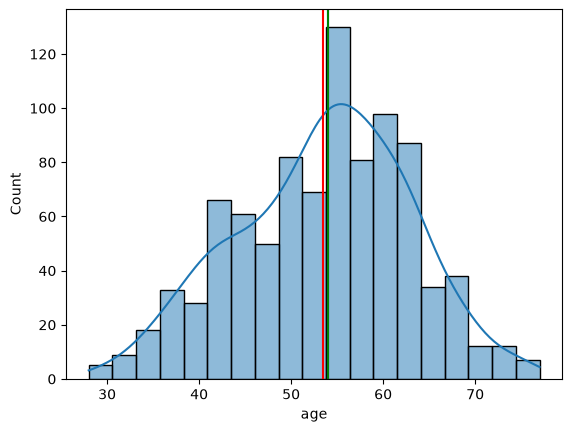

In [11]:
# plot the mean, median, mode of age column
sns.histplot(df['age'], kde=True)
plt.axvline(df['age'].mean(), color= 'red')
plt.axvline(df['age'].median(), color= 'blue')
plt.axvline(df['age'].mode()[0], color= 'green')

# print value of mean, median, mode of age column
print('Mean:', df['age'].mean())
print('Median:', df['age'].median())
print('Mode:', df['age'].mode()[0])

In [12]:
# plot the histogram of age column using plotly and coloring this by sex

fig = px.histogram(data_frame=df, x='age', color='sex')
fig.show()

In [13]:
# find the values of sex column
df['sex'].value_counts()

sex
Male      726
Female    194
Name: count, dtype: int64

In [14]:
# calculate percentage of male and female value counts in the data
male_count= 726
female_count = 194
total_count = male_count+ female_count

# calculate percentage
male_percentage = (male_count / total_count) * 100
female_percentage = (female_count / total_count) * 100

# display results
print(f'Male percentage in data: {male_percentage:.2f}%')
print(f'female percentage in data: {female_percentage:.2f}%')

# difference
difference_percentage = ((male_count - female_count) / female_count) * 100
print(f'Males are: {difference_percentage:.2f}% more than females')

Male percentage in data: 78.91%
female percentage in data: 21.09%
Males are: 274.23% more than females


In [15]:
# find the value count of age column by grouping by sex column
df.groupby('sex')['age'].value_counts()

sex     age
Female  54     15
        51     11
        62     10
        43      9
        48      9
               ..
Male    71      2
        31      1
        28      1
        33      1
        76      1
Name: count, Length: 91, dtype: int64

In [16]:
# Let's deal with column

# find unique values in dataset
df['dataset'].unique()

<StringArray>
['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
Length: 4, dtype: str

In [17]:
# find unique values count in dataset column
df['dataset'].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [18]:
# plot the countplot of dataset column with plotly
fig = px.bar(df, x= 'dataset', color='sex')
fig.show()

# print the valuecount of dataset column grouped by sex
print(df.groupby('sex')['dataset'].value_counts())

sex     dataset      
Female  Cleveland         97
        Hungary           81
        Switzerland       10
        VA Long Beach      6
Male    Hungary          212
        Cleveland        207
        VA Long Beach    194
        Switzerland      113
Name: count, dtype: int64


In [19]:
# make a plot of age column using plotly and coloring this by dataset column
fig = px.histogram(data_frame=df, x= 'age', color= 'dataset')
fig.show()

# print mean median and mode of the dataset
print(f"Mean of Dataset:{df.groupby('dataset')['age'].mean()}")
print("-----------------------------")
print(f"Median of Dataset:{df.groupby('dataset')['age'].median()}")
print("-----------------------------")
print(f"Mode of Dataset:{df.groupby('dataset')['age'].agg(pd.Series.mode)}")

Mean of Dataset:dataset
Cleveland        54.351974
Hungary          47.894198
Switzerland      55.317073
VA Long Beach    59.350000
Name: age, dtype: float64
-----------------------------
Median of Dataset:dataset
Cleveland        55.5
Hungary          49.0
Switzerland      56.0
VA Long Beach    60.0
Name: age, dtype: float64
-----------------------------
Mode of Dataset:dataset
Cleveland              58
Hungary                54
Switzerland            61
VA Long Beach    [62, 63]
Name: age, dtype: object


### Let's explore cp (Chest Pain) column:

In [20]:
# value count of cp column
df['cp'].value_counts()

cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46
Name: count, dtype: int64

sex     cp             
Female  asymptomatic        70
        atypical angina     61
        non-anginal         53
        typical angina      10
Male    asymptomatic       426
        non-anginal        151
        atypical angina    113
        typical angina      36
Name: count, dtype: int64


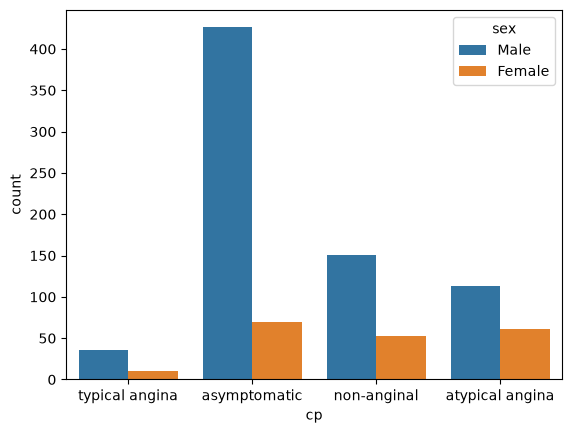

In [21]:
# count plot of cp column by sex column
sns.countplot(df, x='cp', hue='sex')

# print value counts of cp groupby sex
print(df.groupby('sex')['cp'].value_counts())

cp               dataset      
asymptomatic     Cleveland        144
                 VA Long Beach    131
                 Hungary          123
                 Switzerland       98
atypical angina  Hungary          105
                 Cleveland         51
                 VA Long Beach     14
                 Switzerland        4
non-anginal      Cleveland         86
                 Hungary           54
                 VA Long Beach     47
                 Switzerland       17
typical angina   Cleveland         23
                 Hungary           11
                 VA Long Beach      8
                 Switzerland        4
Name: count, dtype: int64


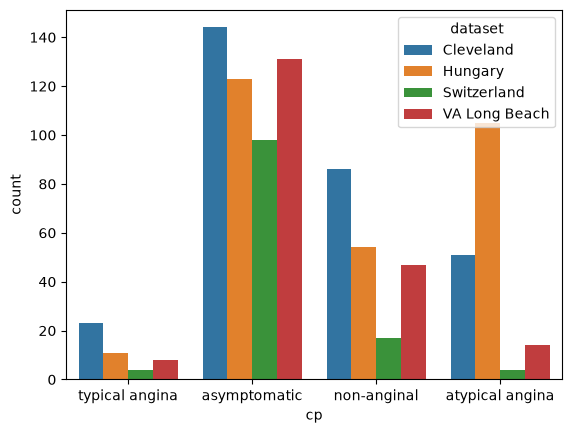

In [22]:
# countplot of cp column by dataset column
sns.countplot(df, x='cp', hue='dataset')

# print valuecount of cp groupby dataset
print(df.groupby('cp')['dataset'].value_counts())

age  cp             
28   atypical angina    1
29   atypical angina    3
30   typical angina     1
31   atypical angina    1
     asymptomatic       1
                       ..
74   non-anginal        2
     typical angina     1
75   asymptomatic       3
76   non-anginal        2
77   asymptomatic       2
Name: count, Length: 156, dtype: int64


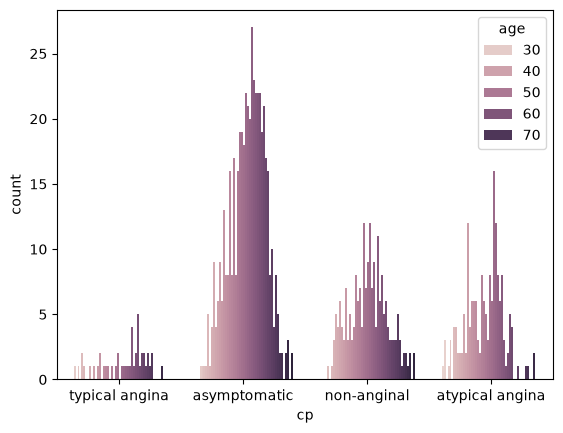

In [23]:
# countplot of cp column by age column
sns.countplot(df, x='cp', hue='age')

# print valuecount of cp column gorupby age column
print(df.groupby('age')['cp'].value_counts())

In [24]:
fig= px.histogram(data_frame=df, x='age', color='cp')
fig.show()

#### Let's explore the trestbps (resting blood pressure) column:

The normal resting blood pressure is 120/80 mm Hg.

In [25]:
# check value counts of trestbps column
df['trestbps'].describe()

count    861.000000
mean     132.132404
std       19.066070
min        0.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64

<Axes: xlabel='trestbps', ylabel='Count'>

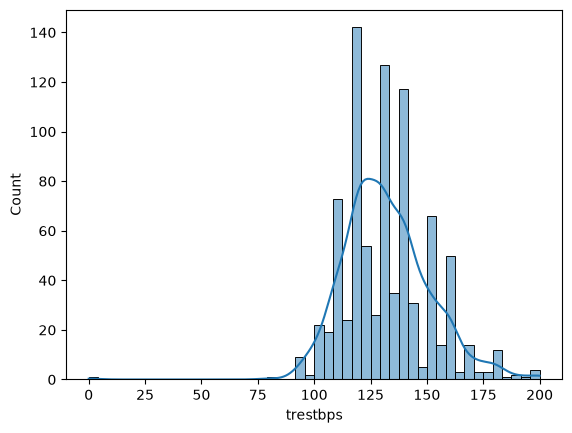

In [26]:
# create a histplot of trestbp column
sns.histplot(df['trestbps'], kde= True)

In [27]:
# deal with missing values in trestbps

# find the percentage of missing values in trestbps column
print(f"Percentage of missing values in trestbps column: {df['trestbps'].isnull().sum()/len(df) * 100 :.2f}%")

Percentage of missing values in trestbps column: 6.41%


In [28]:
# impute the missing values of trestbps column using iterative imputer
# create an object of iterative imputer
imputer1 = IterativeImputer (max_iter=10, random_state= 43)

# fit the imputer on trestbps column
imputer1.fit(df[['trestbps']])

# transform the data
df['trestbps'] = imputer1.transform(df[['trestbps']])

# check the missing values in trestbps
print(f"Missing values in trestbps: {df['trestbps'].isnull().sum()}")

Missing values in trestbps: 0


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  920 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [30]:
# impute missing values using iterative imputer for ca, oldpeak, thalch, chol columns
imputer2 = IterativeImputer(max_iter=10, random_state=43)

# fit_transform the imputer on ca, oldpeak, thalch, chol columns
df['ca'] = imputer2.fit_transform(df[['ca']])
df['oldpeak'] = imputer2.fit_transform(df[['oldpeak']])
df['chol'] = imputer2.fit_transform(df[['chol']])
df['thalch'] = imputer2.fit_transform(df[['thalch']])

#### Let's impute missing values in thal column by using ML models

In [31]:
print(f"The missing values in thal column are: {df['thal'].isnull().sum()}")

The missing values in thal column are: 486


In [32]:
df.isnull().sum()[df.isnull().sum()> 0].sort_values(ascending= False)

thal       486
slope      309
fbs         90
exang       55
restecg      2
dtype: int64

In [33]:
# identify features with missing values in more than 10%
missing_data_cols = df.isnull().sum()[df.isnull().sum() > 0].index.tolist()
missing_data_cols

['fbs', 'restecg', 'exang', 'slope', 'thal']

In [34]:
# seperate columns
categorical_cols = ['thal', 'ca', 'slope', 'exang', 'restecg', 'fbs', 'cp', 'sex', 'num']
bool_cols = ['fbs', 'exang']
numeric_cols = ['oldpeak', 'thalch']

In [35]:
df['thal'].value_counts()

thal
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64

In [36]:
# lets impute other columns with missing values
(df.isnull().sum() / len(df)*100).sort_values(ascending= False)

thal        52.826087
slope       33.586957
fbs          9.782609
exang        5.978261
restecg      0.217391
id           0.000000
sex          0.000000
age          0.000000
chol         0.000000
trestbps     0.000000
cp           0.000000
dataset      0.000000
oldpeak      0.000000
thalch       0.000000
ca           0.000000
num          0.000000
dtype: float64

#### outputs:
1. The minimum age to have a heart disease starts from 28 years old.
2. Most of the people get heart disease at the age of 53-54 years.
3. Most of the males and females are with heart disease at the age of 54-55 years.
4. Male percentage in data:  78.913043%
5. Female percentage in data:  21.086957%
6. Males are:  274.226804% more than females
7. We have highest number of people from Cleaveland(304) and lowest from Switzerland(123).
    1. The highest number of females in this dataset are from cleveland(97) and lowest females are from VA long beach(6).
    2. The highest number of males are from Hungary (212) and lowest from Switzerland (113).
8. `The observations about mean, median and mode of age column, grouped by dataset column.`

    1. Mean of Dataset:\
        Cleveland-------54.351974\
        Hungary-------47.894198\
        Switzerland------55.317073\
        VA Long Beach------59.350000

    2. Median of Dataset:\
        Cleveland------55.5\
        Hungary------49.0\
        Switzerland------56.0\
        VA Long Beach------60.0

    3. Mode of Dataset:\
        Cleveland------58\
        Hungary------54\
        Switzerland------61\
        VA Long Beach------[62, 63]

9. `The observations about cp(Chest Pain) column.`
    1. #### The value count of cp groupby sex are:
        `Female...\`
        asymptomatic.....70\
        atypical angina.....61\
        non-anginal.....53\
        typical angina.....10

        `Male...\`
        asymptomatic.....426\
        non-anginal.....151\
        atypical angina.....113\
        typical angina.....36
    
    2. #### The value count of cp groupby dataset are:
        `Asymptomatic...`\
                Cleveland        144\
                 VA Long Beach    131\
                 Hungary          123\
                 Switzerland       98

        `Atypical angina...`\
                Hungary          105\
                Cleveland         51\
                VA Long Beach     14\
                Switzerland        4

        `Non-anginal...`\
                Cleveland         86\
                Hungary           54\
                VA Long Beach     47\
                Switzerland       17

        `Typical angina...`\
                Cleveland         23\
                Hungary           11\
                VA Long Beach      8\
                Switzerland        4

    3. #### The value count of cp groupby age:

        `age`........`cp`\
        28..........atypical angina    (1)\
        29..........atypical angina    (3)\
        30..........typical angina     (1)\
        31..........atypical angina    (1)\
        31..........asymptomatic       (1)\
        74..........non-anginal        (2)\
        74..........typical angina     (1)\
        75..........asymptomatic       (3)\
        76..........non-anginal        (2)\
        77..........asymptomatic       (2)